## 1. Setup

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
pd.set_option('display.max_colwidth', 60)
print('project root:', ROOT)

project root: D:\STUDY\DL Lab\Project\VisionGuard-Medical


## 2. The trained model — CalibrationMLP

Architecture: `8 → Linear(128) → ReLU → Linear(64) → ReLU → Linear(3)`.

Trained from scratch on **6,514 real IU chest X-ray report claims**. Weak-labelled via MeSH / Problems match. Weights saved to `models/calibration_iu.pt` and loaded automatically at runtime.

In [2]:
from models.calibration import CalibrationMLP, FEATURE_NAMES, STATUS_INDEX, get_model, _IU_WEIGHTS
model = get_model()
print('architecture:')
print(model)
print()
print(f'input features ({len(FEATURE_NAMES)}):')
for i, name in enumerate(FEATURE_NAMES): print(f'  {i}  {name}')
print()
print(f'output classes: {list(STATUS_INDEX.keys())}')
print(f'weights file  : {_IU_WEIGHTS}  ({_IU_WEIGHTS.stat().st_size/1024:.1f} KB)' if _IU_WEIGHTS.exists() else 'no trained weights (would train from synthetic)')

architecture:
CalibrationMLP(
  (net): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=3, bias=True)
  )
)

input features (8):
  0  classifier_prob
  1  classifier_abs_from_midpoint
  2  detector_score
  3  detector_present
  4  polarity_is_negative
  5  polarity_is_uncertain
  6  has_independent_support
  7  has_independent_conflict

output classes: ['supported', 'contradicted', 'indeterminate']
weights file  : D:\STUDY\DL Lab\Project\VisionGuard-Medical\models\calibration_iu.pt  (40.6 KB)


## 3. Pipeline vs non-agentic baseline on bundled fixtures

Three bundled synthetic cases in `datasets/eval_fixtures.json`. Runs the full LangGraph for the agentic column and the all-indeterminate baseline for comparison.

In [3]:
from medical.evaluation import evaluate, load_cases
from medical.claims import AuditReport, TraceEntry, ClaimVerdict, Status
from medical import SYNTHETIC_REPORT, aggregate, extract
from graph.build import run_audit
from baselines.text_only import baseline_audit

def agentic_fn(text, mode):
    return run_audit(text, mode=mode)

def baseline_fn(text, mode):
    source = SYNTHETIC_REPORT if mode == 'synthetic_demo' else text
    claims = extract(source)
    verdicts = [ClaimVerdict(claim_id=c.claim_id, status=Status.INDETERMINATE,
                             explanation='Baseline has no independent evidence.') for c in claims]
    return AuditReport(
        input_type='text' if mode == 'normal' else 'synthetic_demo',
        mode=mode, claims=claims, evidence=[], verdicts=verdicts,
        critic_findings=[], trace=[TraceEntry(node='baseline')],
        aggregate=aggregate(verdicts),
        verification_method='baseline: all indeterminate')

cases = load_cases(ROOT / 'datasets' / 'eval_fixtures.json')
ag = evaluate(cases, agentic_fn).metrics
bl = evaluate(cases, baseline_fn).metrics

pd.DataFrame({
    'metric': ['n_cases', 'n_claims', 'accuracy', 'coverage', 'abstention_rate',
               'F1 supported', 'F1 contradicted', 'F1 indeterminate',
               'recheck_mean', 'latency_ms_median'],
    'agentic':  [ag.n_cases, ag.n_claims, f'{ag.accuracy:.3f}', f'{ag.coverage:.3f}', f'{ag.abstention_rate:.3f}',
                 f"{ag.f1['supported']:.3f}", f"{ag.f1['contradicted']:.3f}", f"{ag.f1['indeterminate']:.3f}",
                 f'{ag.recheck_mean:.2f}', f'{ag.latency_ms_median:.1f}'],
    'baseline': [bl.n_cases, bl.n_claims, f'{bl.accuracy:.3f}', f'{bl.coverage:.3f}', f'{bl.abstention_rate:.3f}',
                 f"{bl.f1['supported']:.3f}", f"{bl.f1['contradicted']:.3f}", f"{bl.f1['indeterminate']:.3f}",
                 f'{bl.recheck_mean:.2f}', f'{bl.latency_ms_median:.1f}'],
}).set_index('metric')

D:\STUDY\DL Lab\Project\VisionGuard-Medical\.venv\Lib\site-packages\langgraph\checkpoint\base\__init__.py:18: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


,agentic,baseline
metric,,
n_cases,3,3
n_claims,8,8
accuracy,0.750,0.625
coverage,0.375,0.000
abstention_rate,0.625,1.000
F1 supported,0.667,0.000
F1 contradicted,0.667,0.000
F1 indeterminate,0.800,0.769
recheck_mean,0.33,0.00


## 4. Pipeline vs 42 hand labels — the headline number

42 claim/image pairs hand-labelled by the project author via the Streamlit *Label Samples* tab. Re-runs the full pipeline (classifier + detector + verifier + calibrator) on each and compares to the human decision.

In [4]:
from medical.evaluation import _compute_metrics, CaseResult

queue  = {it['claim_id']: it for it in json.loads((ROOT/'datasets/iu_xray/labeling_queue.json').read_text())}
labels = json.loads((ROOT/'datasets/iu_xray/hand_labels.json').read_text())
IMG = ROOT / 'datasets' / 'iu_xray' / 'images'

results = []
for cid, lab in labels.items():
    if lab.get('decision') == 'skipped' or cid not in queue: continue
    it = queue[cid]
    img_path = IMG / it['image']
    if not img_path.exists(): continue
    r = run_audit(f"FINDINGS: {it['sentence']}", mode='normal', image_bytes=img_path.read_bytes())
    actual = next((v.status.value for v in r.verdicts
                   if any(c.finding == it['finding'] and c.claim_id == v.claim_id for c in r.claims)),
                  'indeterminate')
    results.append(CaseResult(name=cid, overall_status=r.overall_hallucination_status,
                              per_claim=[{'finding': it['finding'], 'expected': lab['decision'],
                                          'actual': actual, 'matched': actual == lab['decision']}],
                              recheck_count=r.recheck_count, latency_ms=0.0,
                              needs_human_review=r.needs_human_review))

m = _compute_metrics(results)
pd.DataFrame({
    'metric': ['labels evaluated', 'accuracy', 'coverage', 'abstention_rate',
               'precision supported', 'recall supported', 'F1 supported',
               'precision contradicted', 'recall contradicted', 'F1 contradicted',
               'precision indeterminate', 'recall indeterminate', 'F1 indeterminate'],
    'value':  [m.n_claims, f'{m.accuracy:.3f}  ({int(m.accuracy*m.n_claims)} / {m.n_claims})',
               f'{m.coverage:.3f}', f'{m.abstention_rate:.3f}',
               f"{m.precision['supported']:.3f}", f"{m.recall['supported']:.3f}", f"{m.f1['supported']:.3f}",
               f"{m.precision['contradicted']:.3f}", f"{m.recall['contradicted']:.3f}", f"{m.f1['contradicted']:.3f}",
               f"{m.precision['indeterminate']:.3f}", f"{m.recall['indeterminate']:.3f}", f"{m.f1['indeterminate']:.3f}"],
}).set_index('metric')

,value
metric,
labels evaluated,42
accuracy,0.786 (33 / 42)
coverage,0.952
abstention_rate,0.048
precision supported,0.775
recall supported,1.000
F1 supported,0.873
precision contradicted,0.000
recall contradicted,0.000


## 5. Confusion matrix (rows = annotator, columns = pipeline)

The matrix is where the honest failure mode shows up: when the annotator was uncertain, the pipeline often over-claimed `supported`.

In [5]:
cm = pd.DataFrame(m.confusion).T
cm.index.name = 'annotator \\ pipeline'
cm.loc['total'] = cm.sum()
cm['total'] = cm.sum(axis=1)
cm

,supported,contradicted,indeterminate,total
annotator \ pipeline,,,,
supported,31,0,0,31
contradicted,0,0,0,0
indeterminate,9,0,2,11
total,40,0,2,42


In [6]:
# Honest failure-mode summary
indet_rows = m.confusion.get('indeterminate', {})
total_indet = sum(indet_rows.values())
overclaimed = indet_rows.get('supported', 0)
print(f'Of the {total_indet} cases the annotator judged indeterminate,')
print(f'the pipeline over-claimed SUPPORTED {overclaimed} times '
      f'({overclaimed/total_indet*100:.0f}% of ambiguous cases).')
print()
print('This is the primary documented failure mode. Future work:')
print('  - tighten classifier thresholds (currently 0.6 / 0.4)')
print('  - collect contradicted-case labels (0 in the current queue)')
print('  - add CLIP/SigLIP attribute verifier')

Of the 11 cases the annotator judged indeterminate,
the pipeline over-claimed SUPPORTED 9 times (82% of ambiguous cases).

This is the primary documented failure mode. Future work:
  - tighten classifier thresholds (currently 0.6 / 0.4)
  - collect contradicted-case labels (0 in the current queue)
  - add CLIP/SigLIP attribute verifier


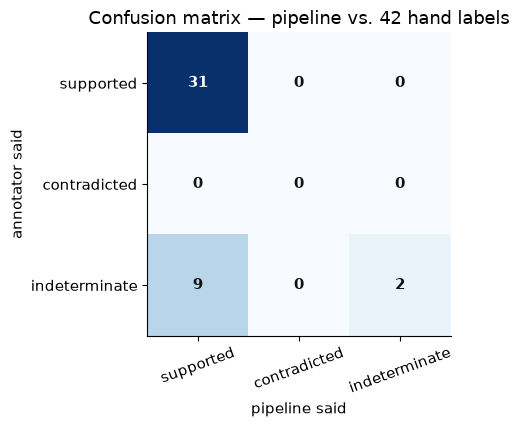

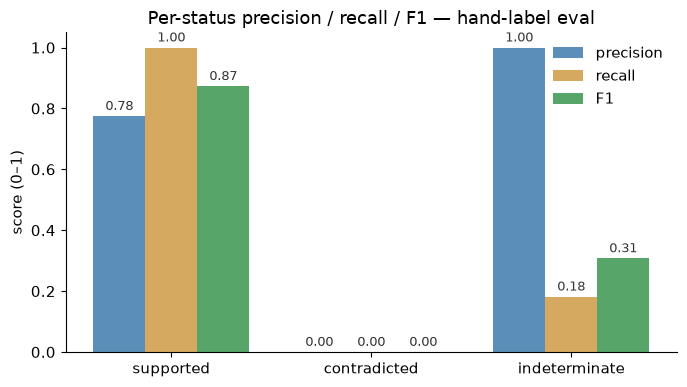

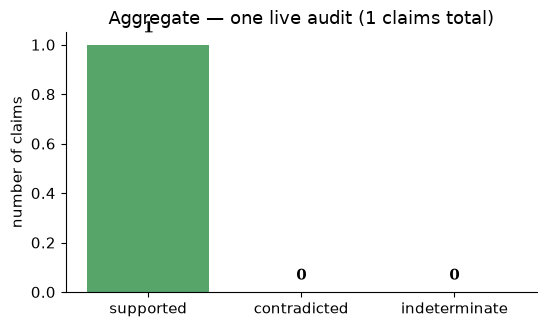

In [7]:
import matplotlib.pyplot as plt
import numpy as np

STATUSES = ('supported', 'contradicted', 'indeterminate')
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})

# ---- Chart 1: Confusion matrix heatmap -----------------------------------
mat = np.array([[m.confusion[r][c] for c in STATUSES] for r in STATUSES])

fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(mat, cmap='Blues')
ax.set_xticks(range(3), STATUSES, rotation=20)
ax.set_yticks(range(3), STATUSES)
ax.set_xlabel('pipeline said')
ax.set_ylabel('annotator said')
ax.set_title('Confusion matrix — pipeline vs. 42 hand labels')
for i in range(3):
    for j in range(3):
        ax.text(j, i, mat[i, j], ha='center', va='center',
                color='white' if mat[i, j] > mat.max()*0.5 else '#111', fontweight='bold')
plt.tight_layout(); plt.show()

# ---- Chart 2: Precision / Recall / F1 per status -------------------------
x = np.arange(len(STATUSES))
w = 0.26
prec = [m.precision[s] for s in STATUSES]
rec  = [m.recall[s]    for s in STATUSES]
f1_  = [m.f1[s]        for s in STATUSES]

fig, ax = plt.subplots(figsize=(7.0, 4.0))
ax.bar(x - w, prec, w, label='precision', color='#5B8FB9')
ax.bar(x,     rec,  w, label='recall',    color='#D6A961')
ax.bar(x + w, f1_,  w, label='F1',        color='#58A569')
ax.set_xticks(x, STATUSES)
ax.set_ylim(0, 1.05)
ax.set_ylabel('score (0–1)')
ax.set_title('Per-status precision / recall / F1 — hand-label eval')
ax.legend(frameon=False, loc='upper right')
for i, (p, r_, f) in enumerate(zip(prec, rec, f1_)):
    for off, v in zip((-w, 0, w), (p, r_, f)):
        ax.text(i + off, v + 0.02, f'{v:.2f}', ha='center', fontsize=9, color='#333')
plt.tight_layout(); plt.show()

# ---- Chart 3: aggregate counts of the live audit (section 6) ------------
agg = r.aggregate
colors = {'supported': '#58A569', 'contradicted': '#CF4647', 'indeterminate': '#D6A961'}
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.bar(list(agg.keys()), list(agg.values()),
       color=[colors[k] for k in agg.keys()])
ax.set_ylabel('number of claims')
ax.set_title(f'Aggregate — one live audit ({sum(agg.values())} claims total)')
for i, (k, v) in enumerate(agg.items()):
    ax.text(i, v + 0.05, str(v), ha='center', fontweight='bold')
plt.tight_layout(); plt.show()

## 6. One live audit — aggregate + per-claim verdicts

Runs the full pipeline on one IU X-ray with a pasted report, shows the AuditReport fields that the frontend displays.

In [8]:
sample = next(iter(sorted(IMG.glob('*.png'))))
report_text = ('FINDINGS: There is a right-sided pleural effusion. The cardiac silhouette shows cardiomegaly.\n'
               'IMPRESSION: Right pleural effusion, likely small.')
r = run_audit(report_text, mode='normal', image_bytes=sample.read_bytes())

print(f'image used                  : {sample.name}')
print(f'audit_id                    : {r.audit_id}')
print(f'overall_hallucination_status: {r.overall_hallucination_status}')
print(f'needs_human_review          : {r.needs_human_review}')
print(f'recheck_count               : {r.recheck_count}')
print(f'aggregate                   : {r.aggregate}')
print(f'trace nodes                 : {[t.node for t in r.trace]}')

image used                  : 10_IM-0002-2001.dcm.png
audit_id                    : a_d349aeaea9ab
overall_hallucination_status: contradicted
needs_human_review          : True
recheck_count               : 0
aggregate                   : {'supported': 0, 'contradicted': 1, 'indeterminate': 2}
trace nodes                 : ['input_validation', 'claim_extraction', 'evidence_retrieval', 'claim_verification', 'fusion_calibration', 'critic', 'risk_gate_human_review']


In [9]:
claims_by_id = {c.claim_id: c for c in r.claims}
pd.DataFrame([{
    'sentence': claims_by_id[v.claim_id].sentence,
    'finding': claims_by_id[v.claim_id].finding,
    'status': v.status.value,
    'calibrated_confidence': f'{v.calibrated_confidence:.2f}' if v.calibrated_confidence is not None else '—',
    'risk': v.risk_level,
    'explanation': v.explanation,
} for v in r.verdicts])

,sentence,finding,status,calibrated_confidence,risk,explanation
0,There is a right-sided pleural effusion.,pleural effusion,indeterminate,0.00,medium,Conflicting independent evidence; requires human review.
1,The cardiac silhouette shows cardiomegaly.,cardiomegaly,contradicted,1.00,medium,1 independent evidence item(s) contradict the claim.
2,"Right pleural effusion, likely small.",pleural effusion,indeterminate,0.00,medium,Claim is hedged/uncertain in the source report; marked i...


In [10]:
# Evidence per claim — the signals that fed the calibration MLP
pd.DataFrame([{
    'claim': claims_by_id[e.claim_id].sentence[:50] + ('…' if len(claims_by_id[e.claim_id].sentence) > 50 else ''),
    'provenance': e.provenance.value,
    'source': e.source,
    'agrees': e.agrees,
    'confidence': f'{e.confidence:.2f}' if e.confidence is not None else '—',
    'has_bbox': e.bbox is not None,
} for e in r.evidence])

,claim,provenance,source,agrees,confidence,has_bbox
0,There is a right-sided pleural effusion.,T0_report_text,original_report,True,—,False
1,There is a right-sided pleural effusion.,image_model,xray_classifier[Effusion],False,0.04,False
2,There is a right-sided pleural effusion.,image_model,grounding_dino[##ly pleural effusion],True,0.47,True
3,The cardiac silhouette shows cardiomegaly.,T0_report_text,original_report,True,—,False
4,The cardiac silhouette shows cardiomegaly.,image_model,xray_classifier[Cardiomegaly],False,0.00,False
5,"Right pleural effusion, likely small.",T0_report_text,original_report,True,—,False
6,"Right pleural effusion, likely small.",image_model,xray_classifier[Effusion],False,0.04,False
7,"Right pleural effusion, likely small.",image_model,grounding_dino[##ly pleural effusion],True,0.47,True
